# Prepare MIR and IF inputs for M2aia Desktop

Load MIR Zarr → export 1650 cm⁻¹ NRRD → create IF plaque mask → check geometry → preview. 
No registration is performed.

In [2]:
from pathlib import Path
import numpy as np
import SimpleITK as sitk
import matplotlib.pyplot as plt
import spatialmirif as mi

from data_path import data_path_zarr_S1_N2, data_path_zarr_S1_N2_info, data_path_if_nrrd_S1_N2, data_path_full_slide_nrrd_S1_N2, output_path_S1_N2

# Original S1_N2 input paths.
mir_zarr = data_path_zarr_S1_N2
mir_info = data_path_zarr_S1_N2_info
if_nrrd = data_path_if_nrrd_S1_N2
bf_nrrd = data_path_full_slide_nrrd_S1_N2
output_dir = output_path_S1_N2
sample_name = "S1_N2"
wavenumber = 1650.0
pz_um = 10.0  # Original setting; verify physical Z spacing in acquisition metadata.
mir_rotate = 0  # Exact multiples of 90 degrees only.
output_dir.mkdir(parents=True, exist_ok=True)

# BF is a reference image only; this tutorial does not register MIR to IF.
for name, path in {"MIR": mir_zarr, "MIR INFO": mir_info, "IF": if_nrrd}.items():
    if not path.exists():
        raise FileNotFoundError(f"{name}: {path}")
print("Input paths verified.")

Input paths verified.


### 1. Load MIR

In [3]:
# Load MIR Zarr with SpatialData/Dask and original processing settings.
mir = mi.ZarrSpectrumReader(
    mir_zarr,
    info_path=mir_info,
    pz=pz_um,
    normalization="None",
    pooling="Maximum",
    image_normalization="None",
    spectral_selection="Nearest",
    tolerance=0.0,
)

if hasattr(mir, "info"):
    mir.info()
else:
    print("MIR dimensions:", mir.GetShape())
    print("MIR spacing (mm):", mir.GetSpacing())

cube = mir.GetCube(lazy=True)
print("Dask cube shape:", cube.shape)
print("Dask chunks:", cube.chunks)
print("SpatialData images:", list(mir.GetSpatialData().images.keys()))



spatialmirif — Dataset Information
---------------------------------------------
Name               : 0
Source             : D:\Project_Cemos\with_pymir\Slide_1\S1_N2\0.zarr
Modality           : MIR
Spectrum type      : ContinuousProfile
Dimensions         : [1560, 2400,    1]
Pixel spacing      : [0.004338, 0.004338, 0.01    ] mm
Origin             : [0., 0., 0.] mm
Direction          : [1., 0., 0., 0., 1., 0., 0., 0., 1.]
Spectra            : 3744000
Spectral bins      : 213
Wavenumber range   : 954.00 to 1802.00 cm^-1
First 10 wavenumbers: [954., 958., 962., 966., 970., 974., 978., 982., 986., 990.]
Intensity dtype    : float32
Storage            : SpatialData + Dask
Dask cube shape: (2400, 1560, 213)
Dask chunks: ((300, 300, 300, 300, 300, 300, 300, 300), (300, 300, 300, 300, 300, 60), (213,))
SpatialData images: ['mir_raw']


c:\Users\arsla\anaconda3\envs\spatialmirif-dev\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 2. Select MIR wavenumber and export NRRD

In [4]:
selected_wavenumbers = mir.GetSelectedWavenumbers(
    wavenumber, tol=0.0, selection="Nearest"
)
print("Requested (cm^-1):", wavenumber)
print("Selected (cm^-1):", selected_wavenumbers.tolist())

# Export the single MIR band as a vector NRRD for M2aia.
wn_label = f"{wavenumber:g}".replace(".", "p")
mir_out = output_dir / f"{sample_name}_MIR_{wn_label}_spatialmirif.nrrd"
mir.WriteNRRD(
    mir_out,
    wavenumbers=[wavenumber],
    dtype=np.float32,
    selection="Nearest",
    tolerance=0.0,
    use_compression=True,
    rotate=mir_rotate,
)

mir_image = sitk.ReadImage(str(mir_out))
print("MIR export:", mir_out)
print("Size:", mir_image.GetSize(), "Spacing (mm):", mir_image.GetSpacing())

Requested (cm^-1): 1650.0
Selected (cm^-1): [1650.0]
MIR export: D:\Project_Cemos\with_pymir\Slide_1\S1_N2\output_with_spatialmirif\S1_N2_MIR_1650_spatialmirif.nrrd
Size: (1560, 2400, 1) Spacing (mm): (0.004338395, 0.004338395, 0.01)


### 3. Load IF and generate plaque sampling mask

In [5]:
# Keep the original sampling-mask parameters.
fluorescence = mi.ImageReader(if_nrrd)
masker = mi.FluorescenceSamplingMask(fluorescence)
masker.Generate(
    object_threshold=20,
    object_min_size=2,
    object_max_size=15,
    min_roundness=0.75,
    tissue_gaussian_sigma=4,
    tissue_threshold=3,
    tissue_min_size=5000,
    tissue_closing_radius=30,
    tissue_hole_area=5000,
    tissue_erosion_iterations=40,
    tissue_erosion_radius=2,
    pixel_size_um=3 * 1.621,  # Original IF pixel-size assumption; verify.
    min_nn_um=140,
    max_nn_um=500,
    max_objects=100,
    circle_radius_um=40,
    random_seed=42,
    preserve_source_geometry=True,
    output_dir=output_dir / "mask_qc",
    sample_name=sample_name,
    save_figures=True,
    save_summary=True,
)
mask_out = output_dir / f"{sample_name}_IF_mask_spatialmirif.nrrd"
masker.WriteNRRD(mask_out)
print("IF mask:", mask_out)
print("Mask stages:", masker.GetStageCounts())

D:\Project_Cemos\pymirifimaging\spatialmirif\spatialmirif\segmentation\FluorescenceSamplingMask.py:127: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  cleaned = morphology.remove_small_objects(
D:\Project_Cemos\pymirifimaging\spatialmirif\spatialmirif\segmentation\FluorescenceSamplingMask.py:130: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  cleaned = morphology.binary_closing(
D:\Project_Cemos\pymirifimaging\spatialmirif\spatialmirif\segmentation\FluorescenceSamplingMask.py:134: FutureWarning: Parameter `area_threshold` is deprecated since version 0.2

IF mask: D:\Project_Cemos\with_pymir\Slide_1\S1_N2\output_with_spatialmirif\S1_N2_IF_mask_spatialmirif.nrrd
Mask stages: {'tissue_components_after_cleanup': 6, 'candidate_objects_after_threshold': 477, 'objects_after_area_roundness_filter': 271, 'objects_before_nn_filter': 271, 'objects_after_nn_filter': 84, 'objects_after_random_cap': 84, 'final_sampling_rois': 84, 'final_positive_pixels': 16789}


### 4. Verify output geometry

In [6]:
# IF and generated mask must match exactly; MIR is on its own grid.
if_image = sitk.ReadImage(str(if_nrrd))
mask_image = sitk.ReadImage(str(mask_out))

assert if_image.GetSize() == mask_image.GetSize(), "IF/mask sizes differ"
assert np.allclose(if_image.GetSpacing(), mask_image.GetSpacing()), "IF/mask spacing differs"
assert np.allclose(if_image.GetOrigin(), mask_image.GetOrigin()), "IF/mask origin differs"
assert np.allclose(if_image.GetDirection(), mask_image.GetDirection()), "IF/mask direction differs"

for name, image in [("MIR", mir_image), ("IF", if_image), ("Mask", mask_image)]:
    print(f"{name:4} | size={image.GetSize()} | spacing={image.GetSpacing()} | origin={image.GetOrigin()}")
print("IF/mask geometry verified.")

MIR  | size=(1560, 2400, 1) | spacing=(0.004338395, 0.004338395, 0.01) | origin=(0.0, 0.0, 0.0)
IF   | size=(2729, 1876, 1) | spacing=(0.004863285016047891, 0.004863285016047891, 0.01) | origin=(0.0024316425080233017, 0.0024316425080233017, 0.0)
Mask | size=(2729, 1876, 1) | spacing=(0.004863285016047891, 0.004863285016047891, 0.01) | origin=(0.0024316425080233017, 0.0024316425080233017, 0.0)
IF/mask geometry verified.


### 5. Preview images

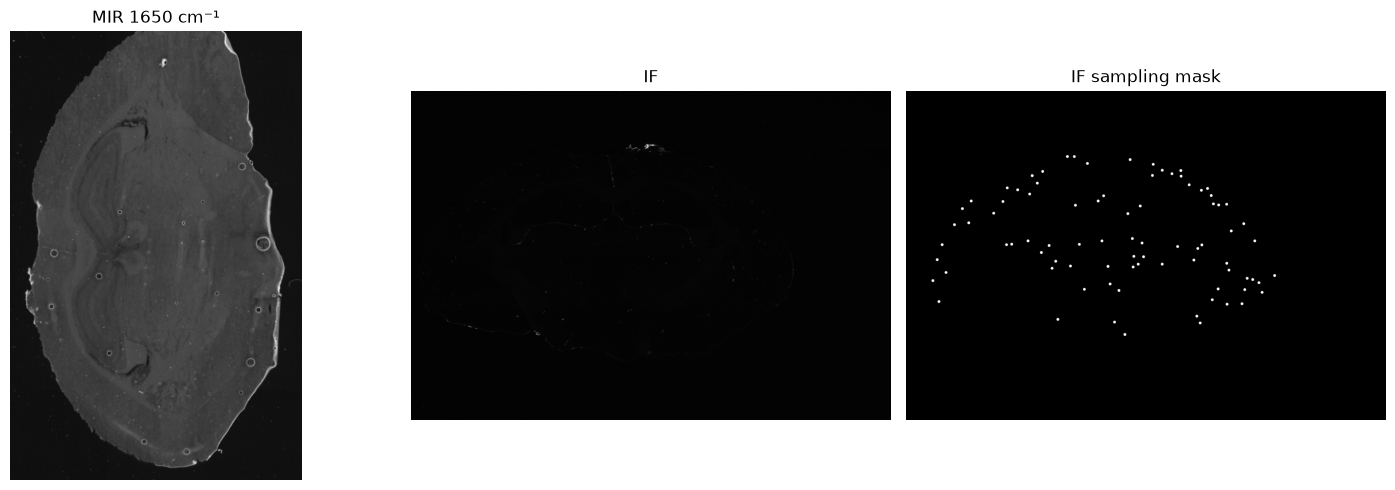

Preview: D:\Project_Cemos\with_pymir\Slide_1\S1_N2\output_with_spatialmirif\S1_N2_MIR_IF_preparation_preview.png


In [7]:
# Separate previews: these images have NOT been spatially aligned.
def preview_2d(image):
    array = sitk.GetArrayFromImage(image)
    array = np.squeeze(array)
    if array.ndim == 3 and array.shape[-1] == 1:
        array = array[..., 0]
    if array.ndim != 2:
        raise ValueError(f"Expected a single 2D image for preview, got {array.shape}")
    return array

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, title, image in zip(
    axes, [f"MIR {selected_wavenumbers[0]:g} cm⁻¹", "IF", "IF sampling mask"],
    [mir_image, if_image, mask_image],
):
    ax.imshow(preview_2d(image), cmap="gray")
    ax.set_title(title)
    ax.axis("off")
fig.tight_layout()
preview_path = output_dir / f"{sample_name}_MIR_IF_preparation_preview.png"
fig.savefig(preview_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Preview:", preview_path)

### 6. M2aia input files

In [8]:
# These are preparation outputs, not registered MIR/IF images.
outputs = {
    "mir_nrrd": mir_out,
    "fluorescence_nrrd": if_nrrd,
    "mask_nrrd": mask_out,
    "mask_summary": output_dir / "mask_qc" / f"{sample_name}_fluorescence_plaque_mask_summary.json",
    "preview": preview_path,
}
for label, path in outputs.items():
    print(f"{label:20}: {path}  |  exists={path.exists()}")

# Optional BF reference; not resampled or used for registration here.
if bf_nrrd.is_file():
    bf_image = sitk.ReadImage(str(bf_nrrd))
    print("BF reference:", bf_nrrd, "| size:", bf_image.GetSize())

mir_nrrd            : D:\Project_Cemos\with_pymir\Slide_1\S1_N2\output_with_spatialmirif\S1_N2_MIR_1650_spatialmirif.nrrd  |  exists=True
fluorescence_nrrd   : D:\Project_Cemos\with_pymir\Slide_1\S1_N2\S1_N2_IF.nrrd  |  exists=True
mask_nrrd           : D:\Project_Cemos\with_pymir\Slide_1\S1_N2\output_with_spatialmirif\S1_N2_IF_mask_spatialmirif.nrrd  |  exists=True
mask_summary        : D:\Project_Cemos\with_pymir\Slide_1\S1_N2\output_with_spatialmirif\mask_qc\S1_N2_fluorescence_plaque_mask_summary.json  |  exists=True
preview             : D:\Project_Cemos\with_pymir\Slide_1\S1_N2\output_with_spatialmirif\S1_N2_MIR_IF_preparation_preview.png  |  exists=True
BF reference: D:\Project_Cemos\test_data_for_pipeline\PPS_Slide_1_BF_10x.nrrd | size: (8999, 3389, 1)
